In [1]:
import zipfile
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Unzip the file
with zipfile.ZipFile('/content/files.zip', 'r') as zip_ref:
    zip_ref.extractall('/content/')

# List the extracted files to find the CSV
import os
print(os.listdir('/content/'))

['.config', 'SHALOM_RAYAN_TERM_2_REPORT.docx', 'DERRYL_NGETA_TERM_2_REPORT.docx', 'files.zip', 'KELVIN_OYWAKO_TERM_2_REPORT.docx', 'BEATAH_WANJIRU_TERM_2_REPORT.docx', 'JOY_MWENDE_TERM_2_REPORT.docx', 'ARIANA_WACHIRA_TERM_2_REPORT.docx', 'NINA_WENDO_TERM_2_REPORT.docx', 'BELVIN_MAUNGU_TERM_2_REPORT.docx', 'ANN_PRISCA_TERM_2_REPORT.docx', 'NEEMA_WAMBUI_TERM_2_REPORT.docx', 'HADASSAH_DAVIS_TERM_2_REPORT.docx', 'HANNAH_WENDO_TERM_2_REPORT.docx', 'ANGUAI_AJANG_TERM_2_REPORT.docx', 'VALERIE_AMANI_TERM_2_REPORT.docx', 'sample_data']


In [6]:
# Load the 'train.csv' dataset
df = pd.read_csv('/content/train.csv')

# Display the first 5 rows of the DataFrame
display(df.head())

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [7]:
# Display DataFrame info for the Titanic dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


### Data Overview and Missing Values

Before proceeding with any analysis, it's crucial to understand the structure of our data and identify any missing values. The `df.info()` command gives us a summary of the DataFrame, including the data types of each column and the number of non-null entries. The `df.isnull().sum()` command helps us quantify the missing values in each column.

In [8]:
# Check for missing values in the Titanic dataset
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


### Data Cleaning and Type Conversion

Based on the initial inspection, we identified missing values in 'Age', 'Cabin', and 'Embarked'. To prepare the data for analysis, we performed the following cleaning steps:

*   **Missing 'Age' values:** Imputed with the median age to maintain the central tendency and avoid distorting the distribution.
*   **Missing 'Embarked' values:** Imputed with the most frequent 'Embarked' value (mode).
*   **'Cabin' column:** Dropped entirely due to a very high percentage of missing values, making it unsuitable for imputation or direct use.
*   **Data Type Conversion:**
    *   'Age' was converted to an integer type for consistency and ease of use.
    *   'Sex' and 'Embarked' were converted to categorical types, which can be more memory-efficient and explicitly indicate their discrete nature for statistical analysis.

In [12]:
# Impute missing 'Age' values with the median
df['Age'] = df['Age'].fillna(df['Age'].median())

# Impute missing 'Embarked' values with the mode
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

# Convert 'Age' to integer type
df['Age'] = df['Age'].astype(int)

# Convert 'Sex' and 'Embarked' to categorical type
df['Sex'] = df['Sex'].astype('category')
df['Embarked'] = df['Embarked'].astype('category')

# Display DataFrame info and missing values again to confirm changes
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   PassengerId  891 non-null    int64   
 1   Survived     891 non-null    int64   
 2   Pclass       891 non-null    int64   
 3   Name         891 non-null    object  
 4   Sex          891 non-null    category
 5   Age          891 non-null    int64   
 6   SibSp        891 non-null    int64   
 7   Parch        891 non-null    int64   
 8   Ticket       891 non-null    object  
 9   Fare         891 non-null    float64 
 10  Embarked     891 non-null    category
dtypes: category(2), float64(1), int64(6), object(2)
memory usage: 64.8+ KB


In [10]:
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


### Summary Statistics

After cleaning the data, generating descriptive statistics for the numerical columns provides a quick overview of their central tendency, dispersion, and shape. This helps in understanding the general characteristics of the dataset.

In [13]:
# Generate summary statistics for numerical columns
display(df.describe())

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.345679,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,13.028212,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,22.000000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,35.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


### Group-Based Insights: Survival Rate by Gender and Passenger Class

To gain insights into survival patterns, we calculated the mean survival rate grouped by 'Sex' and 'Pclass'. This shows the proportion of individuals who survived within each category, highlighting potential factors influencing survival.

In [14]:
# Group-based insights: Survival rate by Sex
display(df.groupby('Sex')['Survived'].mean().reset_index())

/tmp/ipykernel_3217/12542758.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  display(df.groupby('Sex')['Survived'].mean().reset_index())


,Sex,Survived
0,female,0.742038
1,male,0.188908


In [15]:
# Group-based insights: Survival rate by Pclass
display(df.groupby('Pclass')['Survived'].mean().reset_index())

,Pclass,Survived
0,1,0.629630
1,2,0.472826
2,3,0.242363


### Visualizing Survival Rates by Gender and Passenger Class

Bar plots are excellent for comparing categorical data. We used them here to visually represent the survival rates based on gender and passenger class, making the differences immediately apparent.

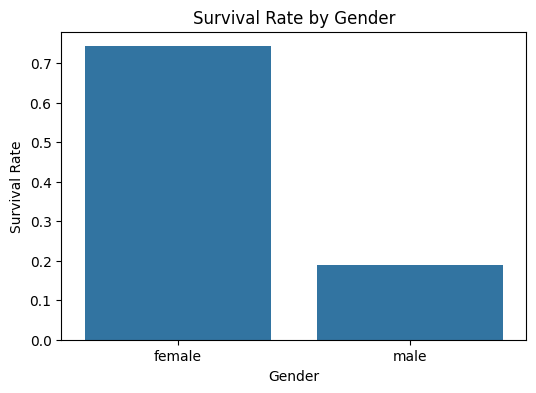

In [18]:
# Visualize survival rate by Sex
plt.figure(figsize=(6, 4))
sns.barplot(x='Sex', y='Survived', data=df.groupby('Sex', observed=False)['Survived'].mean().reset_index())
plt.title('Survival Rate by Gender')
plt.ylabel('Survival Rate')
plt.xlabel('Gender')
plt.show()

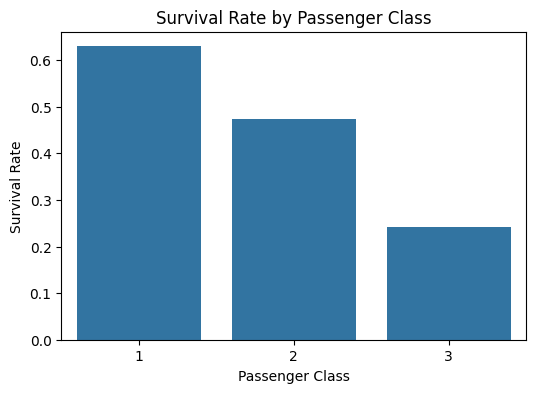

In [19]:
# Visualize survival rate by Pclass
plt.figure(figsize=(6, 4))
sns.barplot(x='Pclass', y='Survived', data=df.groupby('Pclass', observed=False)['Survived'].mean().reset_index())
plt.title('Survival Rate by Passenger Class')
plt.ylabel('Survival Rate')
plt.xlabel('Passenger Class')
plt.show()

### Visualizing Fare Distribution for Survivors vs. Non-Survivors (KDE Plot)

This Kernel Density Estimate (KDE) plot visualizes the probability density of 'Fare' for both survivors and non-survivors. It helps us understand if there's a difference in the fare distribution between the two groups. A higher density at certain fare values indicates a larger concentration of passengers from that group paid those fares.

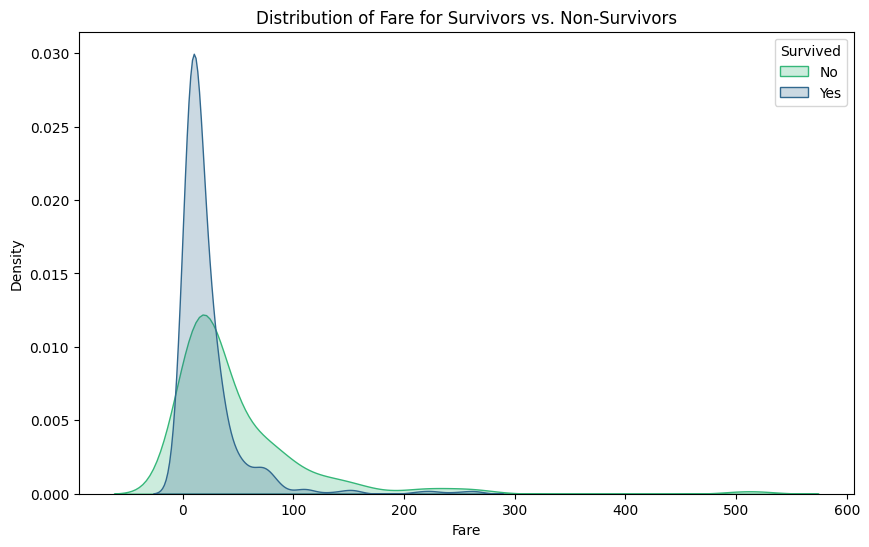

In [20]:
# Visualize the distribution of 'Fare' for survivors vs non-survivors
plt.figure(figsize=(10, 6))
sns.kdeplot(data=df, x='Fare', hue='Survived', fill=True, common_norm=False, palette='viridis')
plt.title('Distribution of Fare for Survivors vs. Non-Survivors')
plt.xlabel('Fare')
plt.ylabel('Density')
plt.legend(title='Survived', labels=['No', 'Yes'])
plt.show()

### Comparing Fare Distributions for Survivors vs. Non-Survivors (Box Plot)

The box plot offers another perspective on the distribution of 'Fare' for survivors and non-survivors. It clearly shows the median, quartiles (25th and 75th percentiles), and potential outliers for each group. This visualization complements the KDE plot by giving us a direct comparison of the spread and central tendency of fares paid by those who survived versus those who did not.

In [3]:
# Load an available dataset since 'titanic.csv' was not found
df = pd.read_csv('/content/sample_data/california_housing_train.csv')

# Display the first 5 rows of the DataFrame
display(df.head())

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
0,-114.31,34.19,15.0,5612.0,1283.0,1015.0,472.0,1.4936,66900.0
1,-114.47,34.40,19.0,7650.0,1901.0,1129.0,463.0,1.8200,80100.0
2,-114.56,33.69,17.0,720.0,174.0,333.0,117.0,1.6509,85700.0
3,-114.57,33.64,14.0,1501.0,337.0,515.0,226.0,3.1917,73400.0
4,-114.57,33.57,20.0,1454.0,326.0,624.0,262.0,1.9250,65500.0


In [4]:
# Display DataFrame info to check data types and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17000 entries, 0 to 16999
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           17000 non-null  float64
 1   latitude            17000 non-null  float64
 2   housing_median_age  17000 non-null  float64
 3   total_rooms         17000 non-null  float64
 4   total_bedrooms      17000 non-null  float64
 5   population          17000 non-null  float64
 6   households          17000 non-null  float64
 7   median_income       17000 non-null  float64
 8   median_house_value  17000 non-null  float64
dtypes: float64(9)
memory usage: 1.2 MB


In [5]:
# Check for missing values
df.isnull().sum()

,0
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,0
population,0
households,0
median_income,0
median_house_value,0
